# M2-T10: Enhanced Visualizations and Dashboards

Builds the Milestone 2 figures and a summary dashboard, including the **High Spoilage Risk vs Normal Velocity** segmentation, and hands them to M2-T05 for the Data Analysis Report. Every number comes from the same code as M2-T02 (sales velocity), M2-T03 (sell-through risk) and M2-T04 (discount flags), so the figures match those notebooks.

**Done when (from the Task Board):** enhanced visualizations and dashboards built, including the High Spoilage Risk vs Normal Velocity segmentation; figures match the data analysis notebook outputs; figures are ready to embed in the M2-T05 report.

| Done-when item | Where it is answered |
|---|---|
| Segmentation High Spoilage Risk vs Normal Velocity | Section 3 (definition) and Figure 1 |
| Figures match the analysis notebooks | Section 2 (guards against the M2-T02 and M2-T03 counts) and the `assert` lines in each section |
| Ready to embed in the M2-T05 report | Section 5 (saved files) and `reports/M2/M2_T10_figure_notes.md` |

| Figure | Content |
|---|---|
| 1 | Segment sizes, spoilage rate and waste by segment |
| 2 | Spoilage and waste by sell-through ratio band |
| 3 | High-risk share and spoilage rate by category |
| 4 | Time needed to sell vs time left before expiry |
| 5 | Spoilage by quality grade inside each segment |
| 6 | Discount depth and spoilage by segment |
| 7 | One-page dashboard |

In [1]:
import hashlib
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'config.py').exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src.config import RAW_DATASET_PATH, FIGURES_M2_DIR, TABLES_DIR, REPORTS_M2_DIR, RANDOM_STATE
from src.m2_velocity import add_sales_velocity, sell_through, RATIO_CAP

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')

for folder in (FIGURES_M2_DIR, TABLES_DIR, REPORTS_M2_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print('Project root:', ROOT)

Project root: c:\Users\Mega Store\Desktop\NHA-5-150


## 1. Load the raw data

The raw file is only read, never modified. Dates are parsed with an explicit format, as in M2-T03.

In [2]:
EXPECTED_SHA256 = 'de94302b867c9debedfd45c431306623fdfc038f5ed8ca17736339b4460a6674'

df = pd.read_csv(RAW_DATASET_PATH)
if 'day_of_week' not in df.columns:
    df = df.rename(columns={[c for c in df.columns if str(c).startswith('Unnamed')][0]: 'day_of_week'})

for c in ['transaction_date', 'expiration_date']:
    is_iso = df[c].astype(str).str.match(r'^\d{4}-\d{2}-\d{2}').all()
    df[c] = pd.to_datetime(df[c], format='%Y-%m-%d' if is_iso else '%m/%d/%Y', errors='raise')

sha = hashlib.sha256(RAW_DATASET_PATH.read_bytes()).hexdigest()
print('SHA256:', sha)
print('Shape :', df.shape)

assert sha == EXPECTED_SHA256, 'Different dataset version'
assert df.shape == (100_000, 42)
assert df['record_id'].is_unique
assert df[['was_spoiled', 'waste_pct', 'discount_pct', 'markdown_applied', 'quality_grade', 'category']].notna().all().all()

SHA256: de94302b867c9debedfd45c431306623fdfc038f5ed8ca17736339b4460a6674
Shape : (100000, 42)


## 2. Rebuild the M2-T02 and M2-T03 columns

`current_stock` is `initial_quantity`, as defined in M2-T03. The velocity and sell-through functions are in `src/m2_velocity.py` and use the same logic as the two notebooks (earlier batches only, `product_name` x `store_id`, 7-day window, category-store fallback). Outcome columns are used only to describe the segments in the figures, never to build them.

In [3]:
df['current_stock'] = df['initial_quantity']
feat = add_sales_velocity(df)
feat['sell_through_risk'], feat['sell_through_ratio'], feat['at_risk'], feat['risk_status'] = sell_through(feat, 'sales_velocity_per_day')

status_counts = feat['risk_status'].value_counts()
source_counts = feat['velocity_source'].value_counts()
print(status_counts.to_string())
print()
print(source_counts.to_string())

assert len(feat) == len(df) and feat['record_id'].is_unique
assert status_counts['at_risk'] == 56_576
assert status_counts['at_risk_zero_velocity'] == 2_027
assert status_counts['ok'] == 40_821
assert status_counts['no_history'] == 576
assert source_counts['product_store_7d'] == 25_415
assert source_counts['category_store_avg'] == 74_009
assert round(100 * feat['at_risk'].mean(), 1) == 58.9

risk_status
at_risk                  56576
ok                       40821
at_risk_zero_velocity     2027
no_history                 576

velocity_source
category_store_avg    74009
product_store_7d      25415
no_history              576


**Conclusion:** the counts are identical to the M2-T02 and M2-T03 notebooks: 56,576 `at_risk`, 2,027 `at_risk_zero_velocity`, 40,821 `ok` and 576 `no_history` batches, and 58.9% of the batches with a velocity are flagged.

## 3. The segmentation

`sell_through_risk` is the number of days needed to sell the stock at the earlier batches' daily speed. A batch is **High spoilage risk** when it would not sell out before expiry (`sell_through_ratio` above 1, or zero velocity with stock in hand). Every other batch with a velocity is **Normal velocity**. The 576 batches with no earlier data have no flag in M2-T03 and are left out of the figures.

The rule sits in one cell. If the team defines the segments differently, only this cell changes and every figure and table is rebuilt.

In [4]:
SEGMENT_RULE = {
    'at_risk': 'High spoilage risk',
    'at_risk_zero_velocity': 'High spoilage risk',
    'ok': 'Normal velocity',
}
SEGMENTS = ['High spoilage risk', 'Normal velocity']
COLORS = {'High spoilage risk': '#c8553d', 'Normal velocity': '#3b6ea8'}

feat['segment'] = feat['risk_status'].map(SEGMENT_RULE)
seg = feat[feat['segment'].notna()].copy()

seg['discount_tier'] = pd.cut(seg['discount_pct'], bins=[-0.001, 0.0, 0.30, 0.50, 1.0],
                              labels=['none', 'light', 'medium', 'deep']).astype(str)
TIERS = ['none', 'light', 'medium', 'deep']

full_tier = pd.cut(df['discount_pct'], bins=[-0.001, 0.0, 0.30, 0.50, 1.0], labels=TIERS).value_counts()
assert full_tier['none'] == 69_349 and full_tier['light'] == 18_403
assert full_tier['medium'] == 5_805 and full_tier['deep'] == 6_443

assert len(seg) == 99_424
overall_spoil = seg['was_spoiled'].mean()
print('Batches in the segmentation:', len(seg), '| left out (no history):', int(feat['segment'].isna().sum()))
print('Overall spoilage rate:', round(100 * overall_spoil, 1), '%')

Batches in the segmentation: 99424 | left out (no history): 576
Overall spoilage rate: 19.4 %


**Conclusion:** 99,424 batches are segmented and 576 are left out. The discount tiers use the same cut points as M2-T04 and give the same counts on the full dataset.

In [5]:
def summarize(frame):
    marked = frame[frame['markdown_applied'] == 1]
    return pd.Series({
        'batches': len(frame),
        'share_pct': 100 * len(frame) / len(seg),
        'spoilage_rate_pct': 100 * frame['was_spoiled'].mean(),
        'mean_waste_pct': frame['waste_pct'].mean(),
        'median_stock_units': frame['current_stock'].median(),
        'median_velocity_per_day': frame['sales_velocity_per_day'].median(),
        'median_days_until_expiry': frame['days_until_expiry'].median(),
        'markdown_rate_pct': 100 * frame['markdown_applied'].mean(),
        'mean_discount_when_marked_pct': 100 * marked['discount_pct'].mean(),
        'deep_discount_share_pct': 100 * (frame['discount_tier'] == 'deep').mean(),
    })

seg_table = seg.groupby('segment').apply(summarize, include_groups=False).loc[SEGMENTS].round(2)
seg_table.T

segment,High spoilage risk,Normal velocity
batches,58603.00,40821.00
share_pct,58.94,41.06
spoilage_rate_pct,19.54,19.30
mean_waste_pct,21.31,24.41
median_stock_units,338.00,130.00
median_velocity_per_day,29.70,31.04
median_days_until_expiry,5.00,10.00
markdown_rate_pct,37.23,21.23
mean_discount_when_marked_pct,35.24,27.30
deep_discount_share_pct,9.13,2.62


## 4. Figures

In [6]:
def bar_labels(ax, fmt='{:.1f}', suffix='', pad=0.01):
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(fmt.format(h) + suffix, (p.get_x() + p.get_width() / 2, h),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points',
                    bbox=dict(facecolor='white', edgecolor='none', pad=1.5), zorder=5)

def p_segment_size(ax):
    vals = seg_table['batches'].astype(int)
    ax.bar(SEGMENTS, vals, color=[COLORS[s] for s in SEGMENTS])
    for i, s in enumerate(SEGMENTS):
        ax.annotate(f"{vals[s]:,}\n({seg_table.loc[s, 'share_pct']:.1f}%)", (i, vals[s]), ha='center', va='bottom', fontsize=9,
                    xytext=(0, 3), textcoords='offset points')
    ax.set_ylim(0, vals.max() * 1.18)
    ax.set_title('Batches per segment')
    ax.set_ylabel('Batches')

def p_spoilage(ax):
    ax.bar(SEGMENTS, seg_table['spoilage_rate_pct'], color=[COLORS[s] for s in SEGMENTS])
    ax.axhline(100 * overall_spoil, color='black', ls='--', lw=1, label=f'Overall {100 * overall_spoil:.1f}%')
    bar_labels(ax, suffix='%')
    ax.set_ylim(0, 30)
    ax.set_title('Spoilage rate by segment')
    ax.set_ylabel('Spoiled batches (%)')
    ax.legend(loc='upper right', fontsize=8)

def p_waste(ax):
    ax.bar(SEGMENTS, seg_table['mean_waste_pct'], color=[COLORS[s] for s in SEGMENTS])
    bar_labels(ax, suffix='%')
    ax.set_ylim(0, 32)
    ax.set_title('Mean waste per batch')
    ax.set_ylabel('waste_pct (%)')

bands = pd.cut(seg['sell_through_ratio'], [0, 0.5, 1, 1.5, 3, 10.01], labels=['<=0.5', '0.5-1', '1-1.5', '1.5-3', '>3'])
band_table = seg.groupby(bands, observed=True).agg(batches=('was_spoiled', 'size'),
                                                  spoilage_rate_pct=('was_spoiled', lambda s: 100 * s.mean()),
                                                  mean_waste_pct=('waste_pct', 'mean')).round(2)

def p_ratio_spoilage(ax):
    ax.bar(band_table.index.astype(str), band_table['spoilage_rate_pct'], color='#7a8ca3')
    ax.axhline(100 * overall_spoil, color='black', ls='--', lw=1)
    bar_labels(ax, suffix='%')
    ax.set_ylim(0, 30)
    ax.set_title('Spoilage rate by sell-through ratio')
    ax.set_xlabel('sell_through_ratio band (>3 includes zero velocity)')
    ax.set_ylabel('Spoiled batches (%)')

def p_ratio_waste(ax):
    ax.bar(band_table.index.astype(str), band_table['mean_waste_pct'], color='#a38a7a')
    bar_labels(ax, suffix='%')
    ax.set_ylim(0, 34)
    ax.set_title('Mean waste by sell-through ratio')
    ax.set_xlabel('sell_through_ratio band (>3 includes zero velocity)')
    ax.set_ylabel('waste_pct (%)')

cat_table = seg.groupby('category').agg(batches=('was_spoiled', 'size'),
                                        high_risk_share_pct=('at_risk', lambda s: 100 * s.mean()),
                                        spoilage_rate_pct=('was_spoiled', lambda s: 100 * s.mean())).round(2)
cat_seg = seg.groupby(['category', 'segment'])['was_spoiled'].mean().unstack().mul(100).round(2)
cat_table = cat_table.join(cat_seg.rename(columns={'High spoilage risk': 'spoilage_high_risk_pct', 'Normal velocity': 'spoilage_normal_pct'}))
cat_order = cat_table.sort_values('high_risk_share_pct').index.tolist()

def p_category_share(ax):
    vals = cat_table.loc[cat_order, 'high_risk_share_pct']
    ax.barh(cat_order, vals, color=COLORS['High spoilage risk'])
    for i, v in enumerate(vals):
        ax.annotate(f'{v:.1f}%', (v, i), va='center', fontsize=9, xytext=(3, 0), textcoords='offset points')
    ax.set_xlim(0, 80)
    ax.set_title('High spoilage risk share by category')
    ax.set_xlabel('Batches flagged (%)')

def p_category_spoilage(ax):
    y = np.arange(len(cat_order))
    for s in SEGMENTS:
        col = 'spoilage_high_risk_pct' if s == SEGMENTS[0] else 'spoilage_normal_pct'
        ax.scatter(cat_table.loc[cat_order, col], y, color=COLORS[s], s=45, label=s, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(cat_order)
    ax.axvline(100 * overall_spoil, color='black', ls='--', lw=1)
    ax.set_title('Spoilage rate by category and segment')
    ax.set_xlabel('Spoiled batches (%)')
    ax.legend(fontsize=8, loc='lower right')

day_table = (seg[seg['sell_through_risk'].notna()].groupby('category')
             .agg(median_days_to_sell=('sell_through_risk', 'median'), median_days_until_expiry=('days_until_expiry', 'median')).round(2))

def p_days_scatter(ax):
    ax.scatter(day_table['median_days_until_expiry'], day_table['median_days_to_sell'], s=70, color='#3b6ea8', zorder=3)
    placed = []
    for name, r in day_table.sort_values('median_days_until_expiry', ascending=False).iterrows():
        lx, ly = np.log10(r['median_days_until_expiry']), np.log10(r['median_days_to_sell'])
        k = sum(1 for px, py in placed if abs(px - lx) < 0.3 and abs(py - ly) < 0.1)
        placed.append((lx, ly))
        ax.annotate(name, (r['median_days_until_expiry'], r['median_days_to_sell']), fontsize=8,
                    xytext=(0, 8 if k % 2 == 0 else -16), textcoords='offset points', ha='center')
    lim = [0.8, 500]
    ax.plot(lim, lim, 'k--', lw=1, label='sells out exactly at expiry')
    ax.set(xscale='log', yscale='log', xlim=lim, ylim=lim, xlabel='Median days until expiry',
           ylabel='Median days needed to sell the stock')
    ax.set_title('Time to sell vs time left, by category')
    ax.legend(fontsize=8, loc='upper left')

grade_table = seg.groupby(['segment', 'quality_grade'])['was_spoiled'].mean().unstack().mul(100).round(2).loc[SEGMENTS]
GRADES = ['A', 'B', 'C']

def p_grade(ax):
    width = 0.38
    x = np.arange(len(GRADES))
    for i, s in enumerate(SEGMENTS):
        vals = grade_table.loc[s, GRADES]
        ax.bar(x + (i - 0.5) * width, vals, width, color=COLORS[s], label=s)
        for xi, v in zip(x + (i - 0.5) * width, vals):
            ax.annotate(f'{v:.1f}%', (xi, v), ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')
    ax.set_xticks(x)
    ax.set_xticklabels([f'Grade {g}' for g in GRADES])
    ax.set_ylim(0, 33)
    ax.set_title('Spoilage by quality grade, inside each segment')
    ax.set_ylabel('Spoiled batches (%)')
    ax.legend(fontsize=8, loc='upper left')

tier_mix = pd.crosstab(seg['segment'], seg['discount_tier'], normalize='index').mul(100).loc[SEGMENTS, TIERS].round(2)
tier_spoil = seg.groupby(['segment', 'discount_tier'])['was_spoiled'].mean().unstack().mul(100).loc[SEGMENTS, TIERS].round(2)
TIER_COLORS = ['#d9d9d9', '#f2c14e', '#e08a3c', '#a63d2f']

def p_tier_mix(ax):
    left = np.zeros(len(SEGMENTS))
    for t, color in zip(TIERS, TIER_COLORS):
        vals = tier_mix[t].values
        ax.barh(SEGMENTS, vals, left=left, color=color, label=t)
        for i, v in enumerate(vals):
            if v >= 4:
                ax.text(left[i] + v / 2, i, f'{v:.0f}%', ha='center', va='center', fontsize=8)
        left += vals
    ax.set_xlim(0, 100)
    ax.invert_yaxis()
    ax.set_title('Discount tier mix by segment')
    ax.set_xlabel('Batches (%)')
    ax.legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2))

def p_tier_spoilage(ax):
    width = 0.38
    x = np.arange(len(TIERS))
    for i, s in enumerate(SEGMENTS):
        ax.bar(x + (i - 0.5) * width, tier_spoil.loc[s, TIERS], width, color=COLORS[s], label=s)
    ax.axhline(100 * overall_spoil, color='black', ls='--', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(TIERS)
    ax.set_ylim(0, 30)
    ax.set_title('Spoilage rate by discount tier and segment')
    ax.set_ylabel('Spoiled batches (%)')
    ax.legend(fontsize=8, loc='upper right')

def save(fig, name):
    path = FIGURES_M2_DIR / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return path

### Figure 1: segment sizes, spoilage and waste

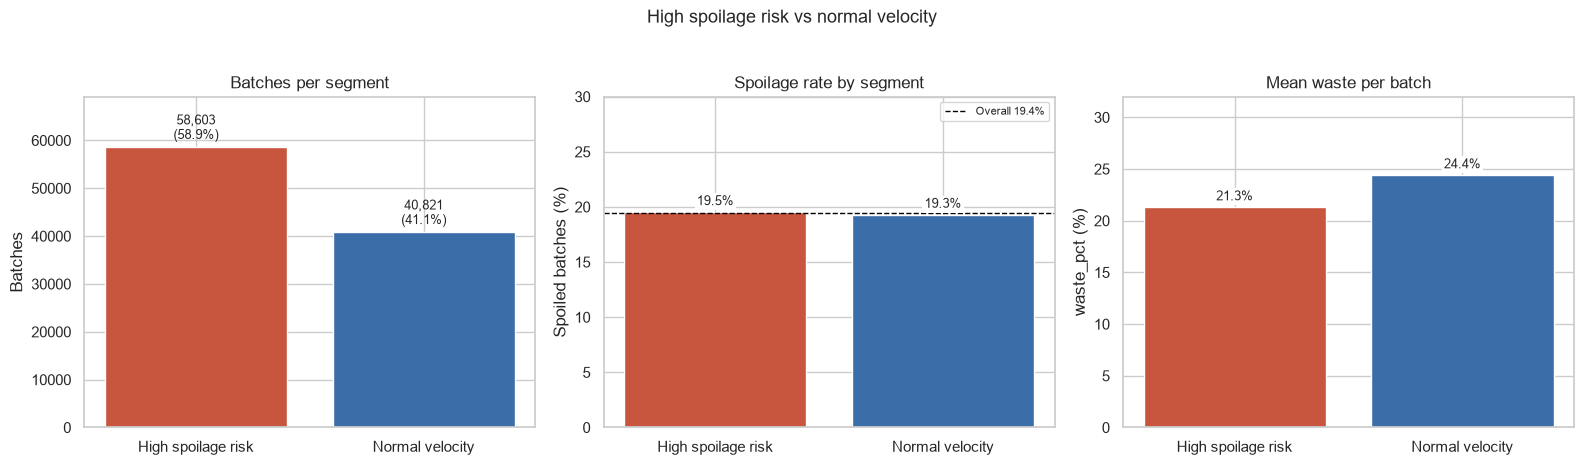

                    batches  share_pct  spoilage_rate_pct  mean_waste_pct
segment                                                                  
High spoilage risk  58603.0      58.94              19.54           21.31
Normal velocity     40821.0      41.06              19.30           24.41
chi-square p-value for spoilage by segment: 0.357


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
p_segment_size(axes[0])
p_spoilage(axes[1])
p_waste(axes[2])
fig.suptitle('High spoilage risk vs normal velocity', fontsize=13, y=1.03)
fig.tight_layout()
FIG1 = save(fig, 'M2_T10_01_segment_overview.png')

chi2, p_seg, _, _ = stats.chi2_contingency(pd.crosstab(seg['segment'], seg['was_spoiled']))
print(seg_table[['batches', 'share_pct', 'spoilage_rate_pct', 'mean_waste_pct']])
print('chi-square p-value for spoilage by segment:', round(p_seg, 3))

assert seg_table.loc['High spoilage risk', 'batches'] == 58_603 and seg_table.loc['Normal velocity', 'batches'] == 40_821
assert round(seg_table.loc['High spoilage risk', 'share_pct'], 1) == 58.9
assert round(seg_table.loc['High spoilage risk', 'spoilage_rate_pct'], 1) == 19.5
assert round(seg_table.loc['Normal velocity', 'spoilage_rate_pct'], 1) == 19.3
assert round(seg_table.loc['High spoilage risk', 'mean_waste_pct'], 1) == 21.3
assert round(seg_table.loc['Normal velocity', 'mean_waste_pct'], 1) == 24.4
assert p_seg > 0.05

**Conclusion:** 58.9% of the batches fall in the High spoilage risk segment (58,603 batches) and 41.1% in Normal velocity (40,821). The two segments spoil at almost the same rate: 19.5% against 19.3% (chi-square p = 0.36, not significant), close to the overall 19.4%. Waste goes the other way: the high-risk segment loses less per batch (21.3% against 24.4%). The segmentation says how likely a batch is to remain unsold, not how likely it is to spoil, which matches the M2-T03 finding.

### Figure 2: graded view by sell-through ratio

The yes/no flag is coarse (M2-T03), so the ratio itself is shown in bands.

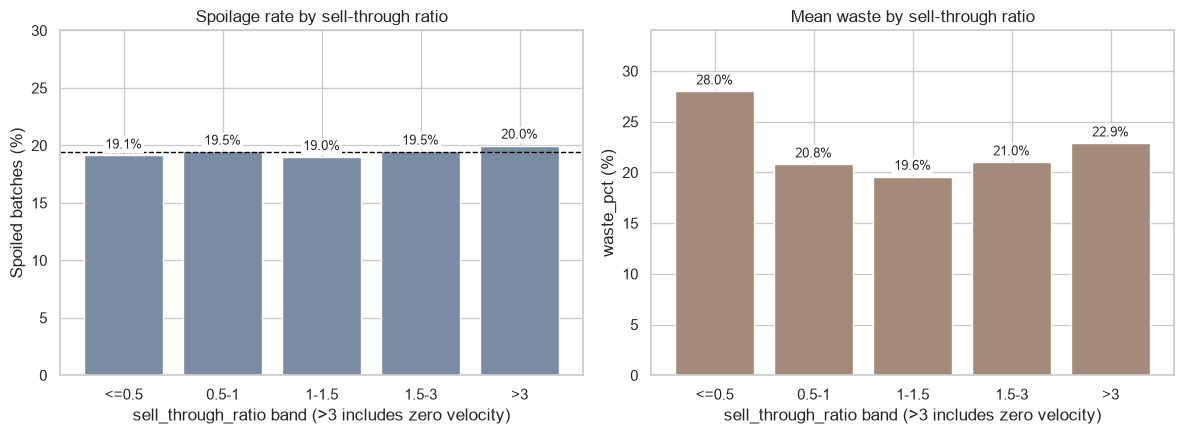

                    batches  spoilage_rate_pct  mean_waste_pct
sell_through_ratio                                            
<=0.5                 20447              19.13           28.00
0.5-1                 20374              19.47           20.80
1-1.5                 15698              19.00           19.59
1.5-3                 21459              19.48           21.01
>3                    21446              19.99           22.88


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
p_ratio_spoilage(axes[0])
p_ratio_waste(axes[1])
fig.tight_layout()
FIG2 = save(fig, 'M2_T10_02_ratio_bands.png')

print(band_table)
assert band_table['batches'].sum() == len(seg)
assert band_table['spoilage_rate_pct'].between(18.9, 20.1).all()
assert round(band_table.loc['<=0.5', 'mean_waste_pct'], 1) == 28.0
assert round(band_table.loc['>3', 'mean_waste_pct'], 1) == 22.9
stock_by_band = seg.groupby(bands, observed=True)['current_stock'].median()
assert stock_by_band.iloc[0] == 73 and stock_by_band.iloc[1:].between(210, 366).all()

**Conclusion:** spoilage stays between 19.0% and 20.0% in every ratio band, so a higher ratio does not mean more spoilage in this file. Waste falls from 28.0% in the lowest band to about 20% to 21% in the middle bands and rises to 22.9% above 3. The lowest band has the highest waste because it holds the smallest stocks (median 73 units against 210 to 366 in the other bands), and small batches lose a larger share (the batch-size effect in M2-T03).

### Figure 3: categories

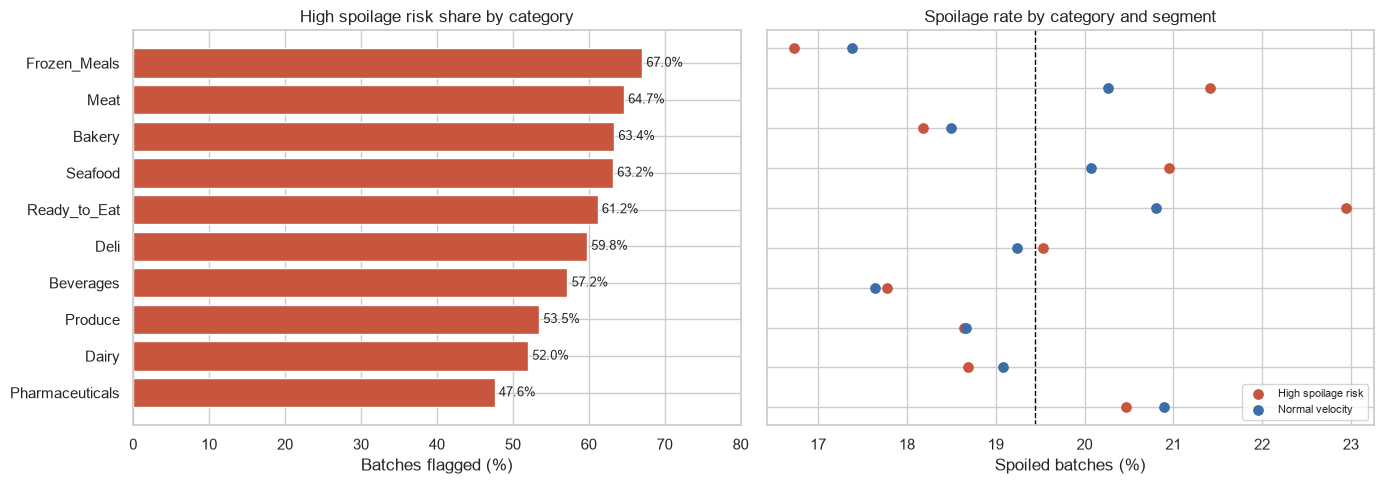

                 batches  high_risk_share_pct  spoilage_rate_pct  \
category                                                           
Pharmaceuticals    10061                47.63              20.69   
Dairy               9905                52.01              18.88   
Produce             9943                53.47              18.65   
Beverages           9838                57.19              17.72   
Deli                9935                59.78              19.42   
Ready_to_Eat        9990                61.18              22.12   
Seafood             9902                63.21              20.62   
Bakery              9985                63.36              18.30   
Meat                9998                64.65              21.00   
Frozen_Meals        9867                67.05              16.95   

                 spoilage_high_risk_pct  spoilage_normal_pct  
category                                                      
Pharmaceuticals                   20.47                20

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
p_category_share(axes[0])
p_category_spoilage(axes[1])
axes[1].set_yticklabels([])
fig.tight_layout()
FIG3 = save(fig, 'M2_T10_03_category_segments.png')

print(cat_table.loc[cat_order])
assert 67.0 <= cat_table.loc['Frozen_Meals', 'high_risk_share_pct'] <= 67.1
assert round(cat_table.loc['Pharmaceuticals', 'high_risk_share_pct'], 1) == 47.6
assert cat_table['batches'].sum() == len(seg)

**Conclusion:** the share of high-risk batches ranges from 47.6% (Pharmaceuticals) to about 67% (Frozen_Meals), with Meat, Bakery and Seafood close behind. Inside each category the two segments spoil at similar rates, and the category itself matters more: Ready_to_Eat, Meat, Pharmaceuticals and Seafood are above the overall rate for both segments, Frozen_Meals below it.

### Figure 4: time needed to sell vs time left

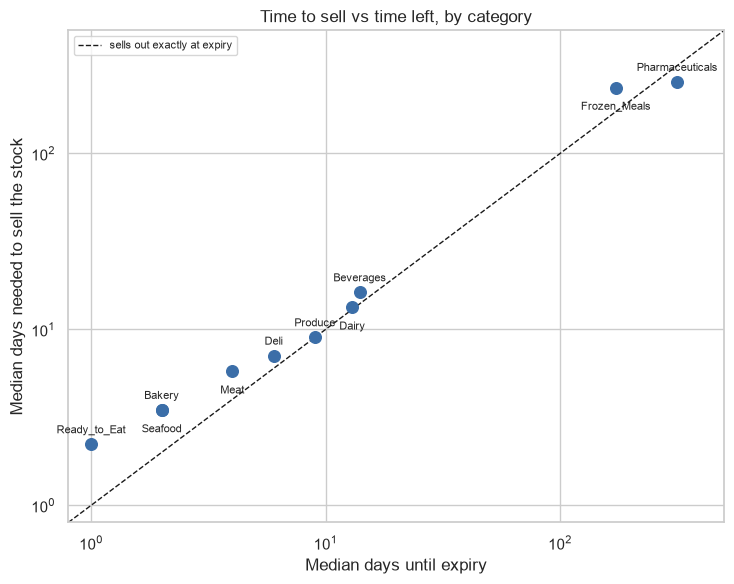

                 median_days_to_sell  median_days_until_expiry  ratio
category                                                             
Pharmaceuticals               254.59                     316.0   0.81
Produce                         9.00                       9.0   1.00
Dairy                          13.35                      13.0   1.03
Beverages                      16.22                      14.0   1.16
Deli                            7.08                       6.0   1.18
Frozen_Meals                  236.88                     173.0   1.37
Meat                            5.78                       4.0   1.44
Bakery                          3.48                       2.0   1.74
Seafood                         3.48                       2.0   1.74
Ready_to_Eat                    2.22                       1.0   2.22


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 6))
p_days_scatter(ax)
fig.tight_layout()
FIG4 = save(fig, 'M2_T10_04_days_to_sell_vs_expiry.png')

day_table['ratio'] = (day_table['median_days_to_sell'] / day_table['median_days_until_expiry']).round(2)
print(day_table.sort_values('ratio'))

**Conclusion:** the points of every category sit close to the dashed line, so for a typical batch the time needed to sell the stock is about the time left. That is why the "ratio above 1" rule flags almost 59% of batches and is better read as a graded score (Figure 2) than as a yes/no.

### Figure 5: quality grade inside each segment

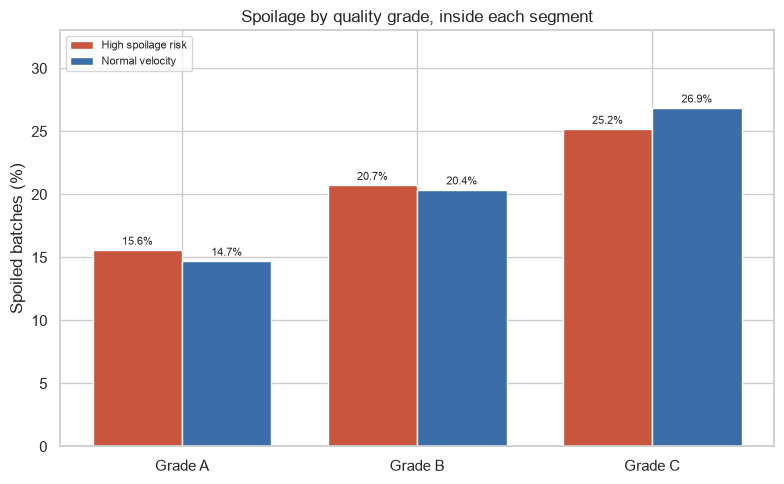

quality_grade           A      B      C
segment                                
High spoilage risk  15.60  20.74  25.19
Normal velocity     14.73  20.38  26.88


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
p_grade(ax)
fig.tight_layout()
FIG5 = save(fig, 'M2_T10_05_quality_grade_by_segment.png')

print(grade_table)
assert round(grade_table.loc['High spoilage risk', 'A'], 1) == 15.6
assert round(grade_table.loc['High spoilage risk', 'C'], 1) == 25.2
assert round(grade_table.loc['Normal velocity', 'A'], 1) == 14.7
assert round(grade_table.loc['Normal velocity', 'C'], 1) == 26.9
assert (grade_table['A'] < grade_table['B']).all() and (grade_table['B'] < grade_table['C']).all()

**Conclusion:** quality grade separates spoilage far more than the segment does, and the pattern is the same in both segments: grade A batches spoil at 15.6% (high risk) and 14.7% (normal), grade C at 25.2% and 26.9%. This agrees with M2-T01, where `quality_grade` was the strongest categorical driver.

### Figure 6: discounts by segment (M2-T04 flags)

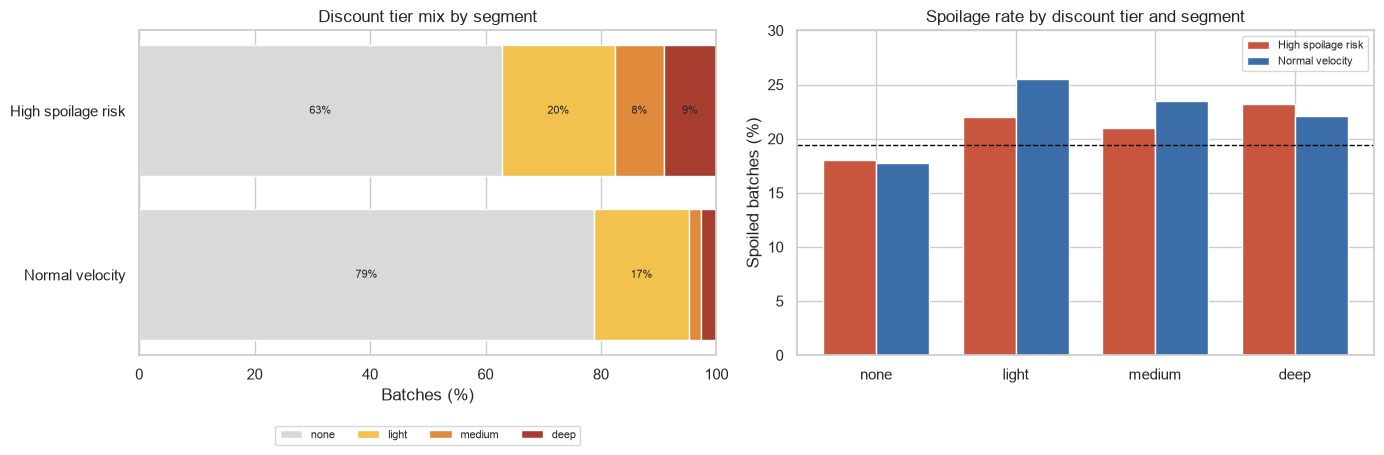

                    markdown_rate_pct  mean_discount_when_marked_pct  \
segment                                                                
High spoilage risk              37.23                          35.24   
Normal velocity                 21.23                          27.30   

                    deep_discount_share_pct  
segment                                      
High spoilage risk                     9.13  
Normal velocity                        2.62  
discount_tier        none  light  medium   deep
segment                                        
High spoilage risk  18.03  22.02   20.97  23.22
Normal velocity     17.80  25.47   23.45  22.08


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
p_tier_mix(axes[0])
p_tier_spoilage(axes[1])
fig.tight_layout()
FIG6 = save(fig, 'M2_T10_06_discounts_by_segment.png')

print(seg_table[['markdown_rate_pct', 'mean_discount_when_marked_pct', 'deep_discount_share_pct']])
print(tier_spoil)
assert round(seg_table.loc['High spoilage risk', 'markdown_rate_pct'], 1) == 37.2
assert round(seg_table.loc['Normal velocity', 'markdown_rate_pct'], 1) == 21.2
assert round(seg_table.loc['High spoilage risk', 'deep_discount_share_pct'], 1) == 9.1
assert round(seg_table.loc['Normal velocity', 'deep_discount_share_pct'], 1) == 2.6
assert round(seg_table.loc['High spoilage risk', 'mean_discount_when_marked_pct'], 1) == 35.2
assert round(seg_table.loc['Normal velocity', 'mean_discount_when_marked_pct'], 1) == 27.3
assert (tier_spoil['none'] < tier_spoil[['light', 'medium', 'deep']].min(axis=1)).all()
assert tier_spoil['none'].between(17.5, 18.5).all()
assert tier_spoil[['light', 'medium', 'deep']].stack().between(20.5, 26).all()

**Conclusion:** the high-risk segment is discounted much more often (37.2% of batches against 21.2%) and more deeply (9.1% deep discounts against 2.6%; mean discount when marked 35.2% against 27.3%). Stores already react to slow-selling stock with markdowns. Undiscounted batches spoil least in both segments (about 18%), while the discounted tiers sit at about 21% to 26%. That is the opposite of a markdown helping: stores discount the batches they already expect to spoil, which is the reverse-causality concern behind the Track 3B design.

### Figure 7: one-page dashboard

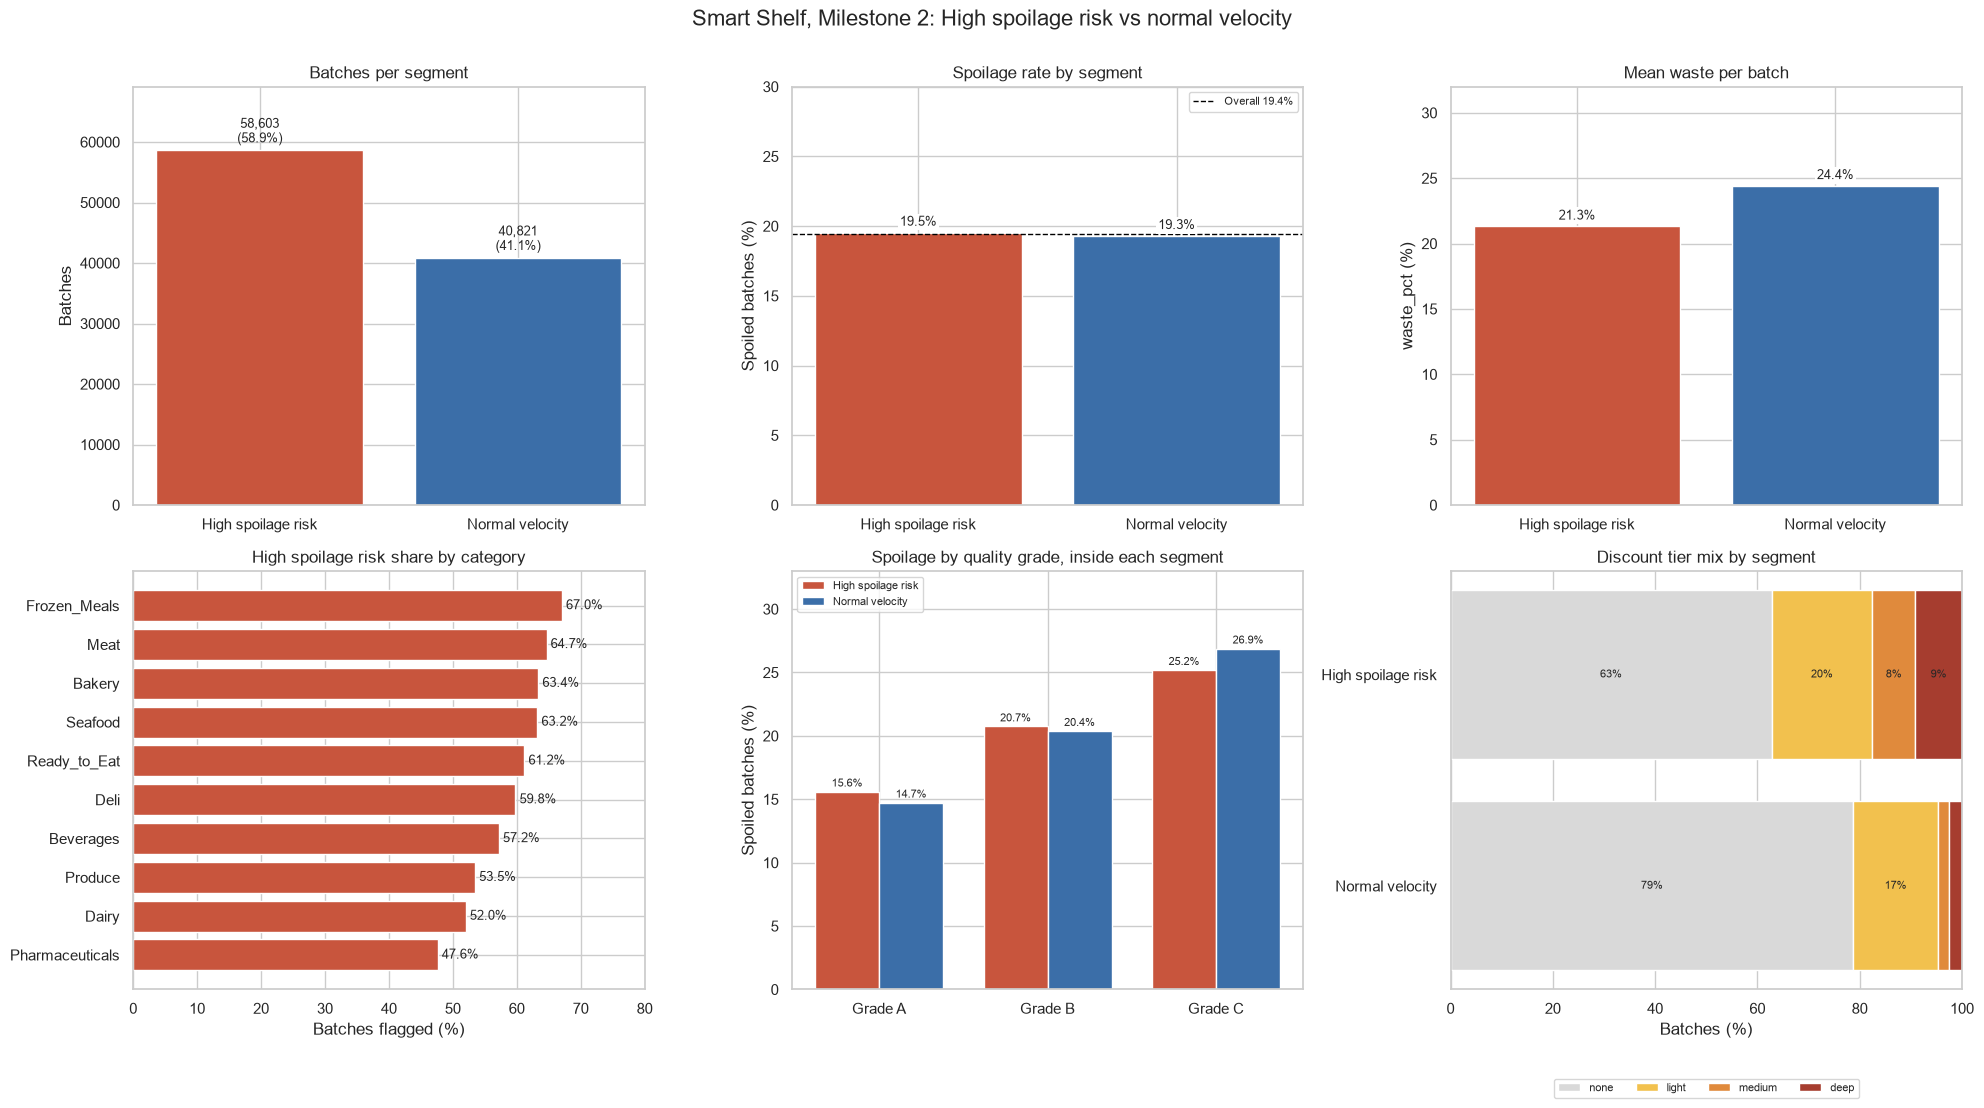

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
p_segment_size(axes[0, 0])
p_spoilage(axes[0, 1])
p_waste(axes[0, 2])
p_category_share(axes[1, 0])
p_grade(axes[1, 1])
p_tier_mix(axes[1, 2])
fig.suptitle('Smart Shelf, Milestone 2: High spoilage risk vs normal velocity', fontsize=16, y=1.0)
fig.tight_layout()
FIG7 = save(fig, 'M2_T10_07_dashboard.png')

**Conclusion:** the dashboard puts the six panels that carry the story on one page: the size of the segments, almost equal spoilage, lower waste in the high-risk segment, the category spread, the quality-grade effect and the heavier discounting of high-risk batches.

## 5. Save the tables and the notes for M2-T05

Figures are already in `reports/figures/m2/`. The tables go to `reports/tables/` and a short list of figures with a suggested caption goes to `reports/M2/` for the report writer.

In [14]:
seg_table.to_csv(TABLES_DIR / 'M2_T10_segment_summary.csv')
cat_table.to_csv(TABLES_DIR / 'M2_T10_category_segments.csv')
band_table.to_csv(TABLES_DIR / 'M2_T10_ratio_bands.csv')
grade_table.to_csv(TABLES_DIR / 'M2_T10_grade_by_segment.csv')

hi, no = 'High spoilage risk', 'Normal velocity'
notes = f'''# M2-T10: figure notes for the M2-T05 report

Segmentation: **High spoilage risk** = batches whose time needed to sell the stock is longer than the days left before expiry (`sell_through_ratio` above 1, or zero velocity with stock). **Normal velocity** = all other batches with a velocity. {int(feat['segment'].isna().sum())} batches with no earlier sales data are excluded.

| Figure | File | Suggested caption |
|---|---|---|
| 1 | `reports/figures/m2/{FIG1.name}` | {seg_table.loc[hi, 'share_pct']:.1f}% of batches are high risk, but both segments spoil at about the same rate ({seg_table.loc[hi, 'spoilage_rate_pct']:.1f}% and {seg_table.loc[no, 'spoilage_rate_pct']:.1f}%). The high-risk segment loses less per batch ({seg_table.loc[hi, 'mean_waste_pct']:.1f}% against {seg_table.loc[no, 'mean_waste_pct']:.1f}% waste). |
| 2 | `reports/figures/m2/{FIG2.name}` | Spoilage stays between {band_table['spoilage_rate_pct'].min():.1f}% and {band_table['spoilage_rate_pct'].max():.1f}% in every sell-through ratio band. |
| 3 | `reports/figures/m2/{FIG3.name}` | The high-risk share runs from {cat_table['high_risk_share_pct'].min():.1f}% ({cat_table['high_risk_share_pct'].idxmin()}) to {cat_table['high_risk_share_pct'].max():.1f}% ({cat_table['high_risk_share_pct'].idxmax()}). |
| 4 | `reports/figures/m2/{FIG4.name}` | For a typical batch the time needed to sell the stock is close to the time left, so the ratio works better as a graded score than as a yes/no flag. |
| 5 | `reports/figures/m2/{FIG5.name}` | Quality grade separates spoilage in both segments (grade A {grade_table.loc[hi, 'A']:.1f}% and {grade_table.loc[no, 'A']:.1f}%, grade C {grade_table.loc[hi, 'C']:.1f}% and {grade_table.loc[no, 'C']:.1f}%). |
| 6 | `reports/figures/m2/{FIG6.name}` | High-risk batches are discounted more often ({seg_table.loc[hi, 'markdown_rate_pct']:.1f}% against {seg_table.loc[no, 'markdown_rate_pct']:.1f}%) and more deeply ({seg_table.loc[hi, 'deep_discount_share_pct']:.1f}% against {seg_table.loc[no, 'deep_discount_share_pct']:.1f}% deep discounts). |
| 7 | `reports/figures/m2/{FIG7.name}` | One-page summary of the segmentation. |

Tables: `reports/tables/M2_T10_segment_summary.csv`, `M2_T10_category_segments.csv`, `M2_T10_ratio_bands.csv`, `M2_T10_grade_by_segment.csv`.
'''
(REPORTS_M2_DIR / 'M2_T10_figure_notes.md').write_text(notes, encoding='utf-8')

for path in (FIG1, FIG2, FIG3, FIG4, FIG5, FIG6, FIG7):
    assert path.exists() and path.stat().st_size > 20_000
print('Saved', len(list(FIGURES_M2_DIR.glob('M2_T10_*.png'))), 'figures, 4 tables and the figure notes')
print('All checks passed')

Saved 7 figures, 4 tables and the figure notes
All checks passed


## Deviations from plan

1. **Segment definition.** The task card does not define "High Spoilage Risk" and "Normal Velocity", so the segmentation uses the M2-T03 flag (`at_risk`, including zero velocity). It is set in one cell (Section 3) and can be changed there without touching the rest.
2. **No interactive HTML.** The figures are static PNG files for the report. Interactive Plotly versions were not built.
3. **Shared code.** The velocity and sell-through functions from M2-T02 and M2-T03 are added to `src/m2_velocity.py` with the same logic, because the two notebooks keep their own copies and the rules ask for reusable logic in `src/`.
4. **Small difference from the M2-T03 text.** M2-T03 reports 19.6% spoilage for the `at_risk` status alone. Here the zero-velocity batches are included in the high-risk segment, which gives 19.5%.